# WAPS Tanker Assessment — Interactive Demo

**Purpose:** demonstrate how the project''s steady-state Python model estimates required engine thrust over a grid of wind values ($V_w,\beta_w$) and how these results are interpreted to calculate the life-cycle cost model.

This notebook is a demonstration of the existing simplified model, not a validated ship-performance prediction.

### Workflow

1. Configure a representative tanker and sail array.
2. Run the steady-state model for true-wind speed/direction pairs.
3. Inspect raw engine thrust and the non-negative value used by the costing workflow.
4. Visualize and export the results.
5. Transfer the thrust values to the workbook for the fuel, emissions, OPEX, CAPEX and discounted life-cycle cost calculations.

## 1. Environment and imports

Place `WAPS_demo.ipynb` in the same project folder as `waps_thrust_model.py`. Install the following listed dependencies:

```bash
python -m pip install -r requirements.txt
```

This notebook imports the classes and solver from the Python model instead of duplicating the model equations.

In [8]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "waps_thrust_model.py").exists():
    if (PROJECT_ROOT / "waps_tanker_project" / "waps_thrust_model.py").exists():
        PROJECT_ROOT = PROJECT_ROOT / "waps_tanker_project"
    elif (PROJECT_ROOT.parent / "waps_thrust_model.py").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "waps_thrust_model.py").exists():
    raise FileNotFoundError(
        "Could not find waps_thrust_model.py. Place this notebook beside the model "
        "or run it from the project directory."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from waps_thrust_model import Sail, SailArray, YachtParameters, YachtModel, solve_one_wind_case

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project directory: . (notebook root)")
print("Outputs directory: outputs/")

Project directory: . (notebook root)
Outputs directory: outputs/


## 2. Configure the vessel and WAPS installation

The initial values mirror the example case in `waps_thrust_model.py`: a large tanker travelling at a prescribed surge speed of 7.2 m/s (14 knots) and six suction-sail units of 150 m² each. 

Technology flags: `1` = soft sail, `2` = rotor sail, `3` = suction sail

Also, the surge coefficient is $D_u$ is calculated from $D_u=R_{reference}/U_{reference}^2$. The vessel's resistance is known at a reference speed of 14knots. 

In [9]:
# Vessel / steady-state settings
params = YachtParameters()
yacht = YachtModel(params)
u_d = 7.2                   # prescribed surge speed [m/s] @set 7.2m/s for 14knots
vessel_heading_deg = 45.0   # heading angle (degrees)
Ne = 0.0                    # external yaw moment [N m]

# WAPS configuration
technology_names = {1: "Soft sail", 2: "Rotor sail (simplified)", 3: "Suction sail (simplified)"}
sail_technology = 3

delta_s_deg = 60.0
lambda1 = 2.0
R_s = 2.0       # rotor radius [m]; stored, but not used in the current rotor CL formula
ks = 12.0
sigma = 0.15
sail_area_each_m2 = 150.0
x_positions_m = [-70.0, -60.0, -50.0]
y_positions_m = [-10.0, 10.0]

# Wind grid: 13 speeds x 10 directions = 130 cases.
wind_speeds_m_s = np.arange(0, 25, 2, dtype=float)      # 0, 2, ..., 24 m/s
wind_angles_deg = np.arange(0, 181, 20, dtype=float)    # 0, 20, ..., 180 deg

tech_params = [np.deg2rad(delta_s_deg), lambda1, R_s, ks, sigma]
sails = [
    Sail(area=sail_area_each_m2, x=x, y=y, tech_params=tech_params, technology=sail_technology)
    for x in x_positions_m for y in y_positions_m
]
sail_array = SailArray(sails)

configuration = pd.DataFrame(
    [
        ("Surge speed", u_d, "m/s"),
        ("Vessel heading", vessel_heading_deg, "deg (metadata only)"),
        ("Surge coefficient Du", params.Du, "kg/m"),
        ("Sail technology", technology_names[sail_technology], ""),
        ("Number of sails", len(sails), "units"),
        ("Area per sail", sail_area_each_m2, "m²"),
        ("Total sail area", len(sails) * sail_area_each_m2, "m²"),
        ("Sheet angle", delta_s_deg, "deg"),
        ("x positions", str(x_positions_m), "m"),
        ("y positions", str(y_positions_m), "m"),
        ("Wind-speed points", len(wind_speeds_m_s), ""),
        ("Wind-angle points", len(wind_angles_deg), ""),
    ], columns=["Parameter", "Value", "Unit / note"]
)
display(configuration)

,Parameter,Value,Unit / note
0,Surge speed,7.2,m/s
1,Vessel heading,45.0,deg (metadata only)
2,Surge coefficient Du,9645.0,kg/m
3,Sail technology,Suction sail (simplified),
4,Number of sails,6,units
5,Area per sail,150.0,m²
6,Total sail area,900.0,m²
7,Sheet angle,60.0,deg
8,x positions,"[-70.0, -60.0, -50.0]",m
9,y positions,"[-10.0, 10.0]",m


## 4. Run the steady-state wind sweep

For every ($V_w,\beta_w$) pair, the model calculates apparent wind, sail-array forces and yaw moment, and solves sway/yaw equilibrium for steady sway velocity and rudder angle while assuming zero yaw rate. It then calculates

$T_{e,raw}=D_u u_d^2-F_{x,WAPS}, \qquad T_{e,used}=\max(0,T_{e,raw})$.

A negative raw value means the model predicts the sails generate more longitudinal force than the estimated resistance at the prescribed speed. Clipping to zero is a rule for the current costing workflow.

In [11]:
rows = []
thrust_used_grid_N = np.full((len(wind_speeds_m_s), len(wind_angles_deg)), np.nan)
thrust_raw_grid_N = np.full_like(thrust_used_grid_N, np.nan)

for i, Vw in enumerate(wind_speeds_m_s):
    for j, beta_deg in enumerate(wind_angles_deg):
        result = solve_one_wind_case(
            yacht=yacht,
            u_d=u_d,
            Vw=float(Vw),
            beta_w=np.deg2rad(float(beta_deg)),
            sail_array=sail_array,
            Ne=Ne,
        )
        rows.append({
            "wind_speed_m_s": float(Vw),
            "beta_w_body_deg_toward": float(beta_deg),
            "vessel_heading_metadata_deg": float(vessel_heading_deg),
            "sail_technology_code": int(sail_technology),
            "sail_technology": technology_names[sail_technology],
            "n_sails": len(sails),
            "sail_area_each_m2": float(sail_area_each_m2),
            **result,
        })
        if result["solver_success"]:
            thrust_used_grid_N[i, j] = result["engine_thrust_used_N"]
            thrust_raw_grid_N[i, j] = result["engine_thrust_raw_N"]

results = pd.DataFrame(rows)
baseline_thrust_N = params.Du * u_d**2
results["engine_only_baseline_thrust_N"] = baseline_thrust_N
results["sails_exceed_estimated_resistance"] = results["engine_thrust_raw_N"] < 0
results["thrust_reduction_pct"] = np.where(
    results["solver_success"] & (results["engine_thrust_raw_N"] >= 0) & (baseline_thrust_N > 0),
    100.0 * (baseline_thrust_N - results["engine_thrust_raw_N"]) / baseline_thrust_N,
    np.nan,
)

n_success = int(results["solver_success"].sum())
n_total = len(results)
n_negative_raw = int((results["engine_thrust_raw_N"] < 0).sum())
print(f"Solved cases: {n_success}/{n_total}")
print(f"Cases with negative raw thrust: {n_negative_raw}")
print(f"Engine-only baseline thrust under the simplified model: {baseline_thrust_N/1e3:,.1f} kN")
if n_success != n_total:
    print("WARNING: at least one nonlinear solve failed. Inspect solver_success and solver_message before using results.")

Solved cases: 130/130
Cases with negative raw thrust: 16
Engine-only baseline thrust under the simplified model: 500.0 kN


## 5. Inspect the output table

Keep both `engine_thrust_raw_N` and `engine_thrust_used_N`. The latter is the non-negative value intended for the current cost workflow. The former helps identify wind conditions, where sail force exceeds the modelled resistance.

In [5]:
show_columns = [
    "wind_speed_m_s", "beta_w_body_deg_toward", "apparent_wind_m_s",
    "sail_Fx_N", "hull_resistance_N", "engine_thrust_raw_N",
    "engine_thrust_used_N", "solver_success", "sails_exceed_estimated_resistance",
]
display(results[show_columns].head(15).round(3))

,wind_speed_m_s,beta_w_body_deg_toward,apparent_wind_m_s,sail_Fx_N,hull_resistance_N,engine_thrust_raw_N,engine_thrust_used_N,solver_success,sails_exceed_estimated_resistance
0,0.0,0.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
1,0.0,20.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
2,0.0,40.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
3,0.0,60.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
4,0.0,80.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
5,0.0,100.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
6,0.0,120.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
7,0.0,140.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
8,0.0,160.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False
9,0.0,180.0,7.200,3413.568,499996.8,496583.232,496583.232,True,False


## 6. Visualize the thrust map

The heatmap displays non-negative engine thrust used in the cost model. Each cell corresponds to a wind-speed / wind-angle pair.

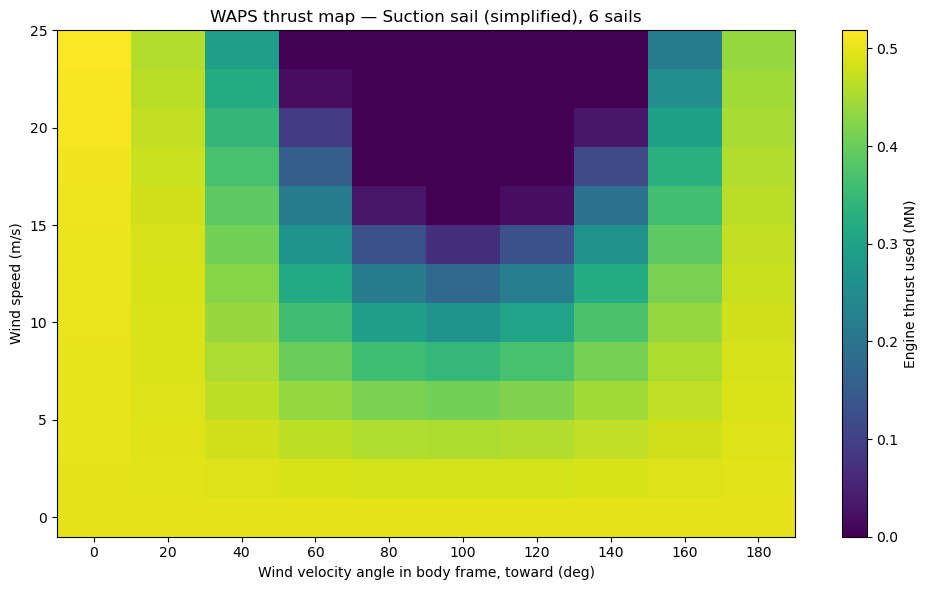

Heatmap saved to: outputs\demo_thrust_heatmap.png


In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(
    wind_angles_deg, wind_speeds_m_s, thrust_used_grid_N / 1e6,
    shading="nearest", cmap="viridis",
)
fig.colorbar(mesh, ax=ax, label="Engine thrust used (MN)")
ax.set_xlabel("Wind velocity angle in body frame, toward (deg)")
ax.set_ylabel("Wind speed (m/s)")
ax.set_title(f"WAPS thrust map — {technology_names[sail_technology]}, {len(sails)} sails")
ax.set_xticks(wind_angles_deg)
fig.tight_layout()
heatmap_path = OUTPUT_DIR / "demo_thrust_heatmap.png"
fig.savefig(heatmap_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Heatmap saved to: {heatmap_path.relative_to(PROJECT_ROOT)}")

## 7. Example comparison at one wind speed

The engine-only baseline is constant with wind direction because the current baseline only includes $D_u u_d^2$.  It does not include wind-induced hull resistance. This comparison is therefore a diagnostic illustration, not a full weather-routing prediction.

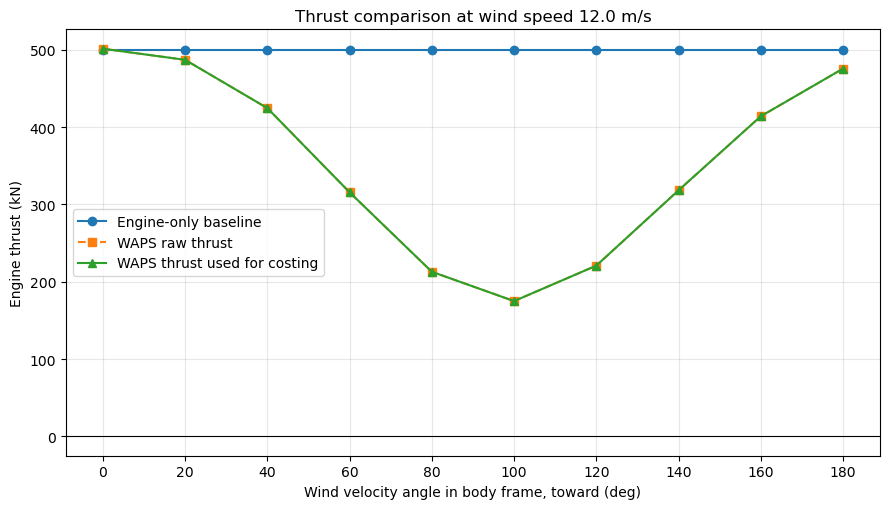

Comparison plot saved to: outputs\demo_thrust_comparison_12ms.png


In [13]:
selected_wind_speed = 12.0  # (m/s):  select a speed included in wind_speeds_m_s
slice_df = results[np.isclose(results["wind_speed_m_s"], selected_wind_speed)].sort_values("beta_w_body_deg_toward")
if slice_df.empty:
    raise ValueError("selected_wind_speed is not present in wind_speeds_m_s")

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(slice_df["beta_w_body_deg_toward"], slice_df["engine_only_baseline_thrust_N"] / 1e3,
        marker="o", label="Engine-only baseline")
ax.plot(slice_df["beta_w_body_deg_toward"], slice_df["engine_thrust_raw_N"] / 1e3,
        marker="s", linestyle="--", label="WAPS raw thrust")
ax.plot(slice_df["beta_w_body_deg_toward"], slice_df["engine_thrust_used_N"] / 1e3,
        marker="^", label="WAPS thrust used for costing")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Wind velocity angle in body frame, toward (deg)")
ax.set_ylabel("Engine thrust (kN)")
ax.set_title(f"Thrust comparison at wind speed {selected_wind_speed:.1f} m/s")
ax.set_xticks(wind_angles_deg)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
comparison_path = OUTPUT_DIR / "demo_thrust_comparison_12ms.png"
fig.savefig(comparison_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Comparison plot saved to: {comparison_path.relative_to(PROJECT_ROOT)}")

## 8. Export results for the Excel workbook

The CSV-to-Excel transfer is currently **MANUAL**. Match both wind speed and angle.  The workbook uses the identical grid and ordering with the original code, however if anything is modified, check it. Before transferring the values, verify that all expected solver cases succeeded and that the excel wind-probability matrix uses the same bins.

In [14]:
csv_path = OUTPUT_DIR / "demo_thrust_results.csv"
results.to_csv(csv_path, index=False)
print(f"CSV exported: {csv_path.relative_to(PROJECT_ROOT)}")
print(f"Rows written: {len(results)}")
print(f"Solver failures: {int((~results['solver_success']).sum())}")
print(f"Negative raw-thrust cases: {int((results['engine_thrust_raw_N'] < 0).sum())}")
display(results[[
    "wind_speed_m_s", "beta_w_body_deg_toward", "engine_thrust_raw_N",
    "engine_thrust_used_N", "solver_success",
]].tail(12).round(3))

CSV exported: outputs\demo_thrust_results.csv
Rows written: 130
Solver failures: 0
Negative raw-thrust cases: 16


,wind_speed_m_s,beta_w_body_deg_toward,engine_thrust_raw_N,engine_thrust_used_N,solver_success
118,22.0,160.0,256495.434,256495.434,True
119,22.0,180.0,443852.031,443852.031,True
120,24.0,0.0,518581.783,518581.783,True
121,24.0,20.0,459604.226,459604.226,True
122,24.0,40.0,288238.646,288238.646,True
123,24.0,60.0,-59734.689,0.000,True
124,24.0,80.0,-461863.084,0.000,True
125,24.0,100.0,-673025.103,0.000,True
126,24.0,120.0,-540197.608,0.000,True
127,24.0,140.0,-162207.901,0.000,True


## 9. Hand-off to the techno-economic workbook

Use `Vessel_Costs_v15_09.xlsx` to continue the analysis. This notebook does **not** edit the workbook.

1. Open `outputs/demo_thrust_results.csv` and verify `solver_success` for each row.
2. Transfer `engine_thrust_used_N` to the designated thrust-input range for the corresponding WAPS case.
3. Match by wind speed and angle and confirm the wind grid and probability matrix align.
4. Save a separate copy or label the workbook clearly so that each result remains traceable to its vessel/sail settings.
5. Compare the engine-only baseline against the same vessel with WAPS under identical operating and economic assumptions.

The final economic comparison can then include annual fuel use and cost, emissions compliance, auxiliary electricity, OPEX, CAPEX and discounted life-cycle cost.

## 10. Assumptions and limitations

- Surge speed is prescribed; only sway/yaw equilibrium is solved, with yaw rate set to zero.
- Hull resistance is approximated as $R_T=D_u u^2$.  calibrate $D_u$ to the selected vessel's resistance and matching reference speed.
- The supplied project documents contain differing illustrative resistance assumptions. Reconcile the selected resistance, reference speed and excel input before interpreting the economic results.
- Sail sheet angle is fixed, not optimized.
- Rotor/suction force relations are simplified. The rotor lift coefficient is imposed rather than computed from a detailed rotor-performance map.
- Rudder-induced longitudinal drag and wind-induced hull resistance are not explicitly included in the surge balance.
- Negative raw thrust is clipped to zero for costing. Sail depowering and acceleration is not simulated.
- Route-specific wind probabilities and economic inputs should be used before making profitability claims.